# Sensitivity of the target gene set to the selection criteria

The 634 target genes (`1_enrichment.ipynb`) are the genes that are **highly variable** (seurat_v3, top 2500 of the
5001-gene panel, whole-cell tumor counts) in at least 2 of the five samples **and cytoplasm-enriched** (pseudobulk
log2FC cyto vs nuc > 0, paired-Wilcoxon FDR < 0.05, after dropping the bottom 10% of genes by total count) in at
least 3 of the five samples.

This notebook asks how many genes other search criteria would give and how they overlap with the current 634.
Varied:

1. **Enrichment criterion**: the current logFC/FDR rule, or a detection rule (cytoplasmic count > 0 in at least
   p% of the sample's tumor cells, p = 5, 10, 20, 30).
2. **HVG basis**: whole-cell counts (current) or the cytoplasmic compartment matrix.
3. **Sample-count thresholds**: HVG in >= N samples (N = 0..5, 0 = no HVG filter) and enriched/detected in >= M
   samples (M = 1..5).

Fixed: `n_top_hvg = 2500` and the per-sample bottom-10% total-count drop (the per-sample gene universe is the set
of genes present in `output/1_exploration/<sample>/enrichment_results.csv`; it is applied to both the logFC and
the detection criteria). Nothing downstream is changed: the 634-gene set and all analyses built on it stay as they
are. Outputs go to `output/1_exploration/gene_set_sensitivity/`.

In [1]:
import os
import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from scipy import sparse

import warnings
warnings.filterwarnings("ignore")
sc.settings.verbosity = 0

/Users/chenyang/miniconda3/envs/AIVC-env/lib/python3.10/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound
/Users/chenyang/miniconda3/envs/AIVC-env/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/Users/chenyang/miniconda3/envs/AIVC-env/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/Users/chenyang/miniconda3/envs/AIVC-env/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_hdf from `annda

In [2]:
# Config (fixed values match 1_enrichment.ipynb)
samples = ["Xenium_5K_BC", "Xenium_5K_OC", "Xenium_5K_CC", "Xenium_5K_LC", "Xenium_5K_Prostate"]
short = {s: s.replace("Xenium_5K_", "") for s in samples}
n_top_hvg = 2500                              # fixed
detect_thresholds = [0.05, 0.10, 0.20, 0.30]  # cytoplasmic detection rate thresholds (detection rule)
n_hvg_range = list(range(0, 6))               # HVG in >= N samples; 0 = no HVG filter
m_range = list(range(1, 6))                   # enriched / detected in >= M samples
current_n, current_m = 2, 3                   # thresholds of the current 634-gene set

gene_set_file = "../../../output/1_exploration/enrichment/overlap_genes_3plus_samples.npy"
out_dir = "../../../output/1_exploration/gene_set_sensitivity/"
os.makedirs(out_dir, exist_ok=True)

current_genes = set(np.load(gene_set_file, allow_pickle=True).tolist())
print(f"Current target gene set: {len(current_genes)} genes")

Current target gene set: 634 genes


## 1. Per-gene, per-sample criteria

One pass over the five samples. For every gene and sample: HVG flag on whole-cell counts (current), HVG flag on
cytoplasmic counts, cytoplasmic detection rate, membership in the fixed gene universe (bottom-10% drop), and the
current logFC/FDR flag read from `enrichment_results.csv`. The long table is saved so that the scenario grid below
can be recomputed without the h5ad files.

In [3]:
rows = []
for sample in samples:
    print("=" * 20 + f" {sample} " + "=" * 20)
    intermediate_path = f"../../../data/{sample}/intermediate_data/"
    processed_path = f"../../../data/{sample}/processed_data/"

    adata = sc.read_h5ad(intermediate_path + "adata.h5ad")
    cell_ids = np.load(processed_path + "cell_ids.npy", allow_pickle=True)
    gene_ids = np.load(processed_path + "gene_ids.npy", allow_pickle=True)
    adata_tumor = adata[adata.obs["cell_id"].isin(cell_ids)].copy()
    del adata
    assert np.array_equal(adata_tumor.var_names.values.astype(str), gene_ids.astype(str)), "gene order mismatch"

    X_cyto = sparse.load_npz(processed_path + "cytoplasmic_expression_matrix.npz").tocsr()
    assert X_cyto.shape == adata_tumor.shape, "compartment matrix shape mismatch"
    n_cells = X_cyto.shape[0]

    # HVG on whole-cell raw counts (current basis)
    sc.pp.highly_variable_genes(adata_tumor, flavor="seurat_v3", n_top_genes=n_top_hvg)
    hvg_cell = adata_tumor.var["highly_variable"].values.copy()

    # HVG on cytoplasmic raw counts (alternative HVG basis)
    ad_cyto = ad.AnnData(X=X_cyto.astype(np.float32), var=pd.DataFrame(index=adata_tumor.var_names))
    sc.pp.highly_variable_genes(ad_cyto, flavor="seurat_v3", n_top_genes=n_top_hvg)
    hvg_cyto = ad_cyto.var["highly_variable"].values.copy()

    # Cytoplasmic detection rate (detection rule)
    detect_frac = np.asarray((X_cyto > 0).mean(axis=0)).ravel()
    cyto_counts = np.asarray(X_cyto.sum(axis=0)).ravel()

    # Current enrichment results (gene universe = genes kept after the bottom-10% drop)
    enr = pd.read_csv(f"../../../output/1_exploration/{sample}/enrichment_results.csv").set_index("gene")

    df = pd.DataFrame({
        "gene": adata_tumor.var_names.values,
        "sample": short[sample],
        "n_tumor_cells": n_cells,
        "hvg_cell": hvg_cell,
        "hvg_cyto": hvg_cyto,
        "cyto_counts": cyto_counts,
        "detect_frac_cyto": detect_frac,
    })
    df["in_universe"] = df["gene"].isin(enr.index)
    df["log2FC_cyto_vs_nuc"] = df["gene"].map(enr["log2FC_cyto_vs_nuc"])
    df["FDR"] = df["gene"].map(enr["FDR"])
    df["enriched_logfc"] = df["in_universe"] & (df["log2FC_cyto_vs_nuc"] > 0) & (df["FDR"] < 0.05)
    for p in detect_thresholds:
        df[f"detect_{int(round(p * 100)):02d}"] = df["in_universe"] & (df["detect_frac_cyto"] >= p)

    # Reproduction check of the saved HVG flag on the genes present in the csv
    saved_hvg = df.set_index("gene").loc[enr.index, "hvg_cell"].values
    n_mismatch = int((saved_hvg != enr["highly_variable"].values).sum())
    print(f"tumor cells {n_cells}; HVG(cell) {hvg_cell.sum()}, HVG(cyto) {hvg_cyto.sum()}, "
          f"HVG(cell) vs saved flag mismatches: {n_mismatch}; universe {df['in_universe'].sum()} genes; "
          f"enriched (logFC) {df['enriched_logfc'].sum()}; "
          + ", ".join(f"detect>={int(round(p*100))}% {df[f'detect_{int(round(p*100)):02d}'].sum()}" for p in detect_thresholds))
    assert n_mismatch == 0, "whole-cell HVG flag does not reproduce the saved flag"
    rows.append(df)
    del adata_tumor, ad_cyto, X_cyto

criteria = pd.concat(rows, ignore_index=True)
criteria.to_csv(out_dir + "gene_sample_criteria.csv", index=False)
print(criteria.shape)

==================== Xenium_5K_BC ====================


tumor cells 102180; HVG(cell) 2500, HVG(cyto) 2500, HVG(cell) vs saved flag mismatches: 0; universe 4502 genes; enriched (logFC) 1158; detect>=5% 712, detect>=10% 283, detect>=20% 74, detect>=30% 26
==================== Xenium_5K_OC ====================


tumor cells 160250; HVG(cell) 2500, HVG(cyto) 2500, HVG(cell) vs saved flag mismatches: 0; universe 4504 genes; enriched (logFC) 1053; detect>=5% 1130, detect>=10% 504, detect>=20% 146, detect>=30% 57
==================== Xenium_5K_CC ====================


tumor cells 221355; HVG(cell) 2500, HVG(cyto) 2500, HVG(cell) vs saved flag mismatches: 0; universe 4504 genes; enriched (logFC) 1244; detect>=5% 492, detect>=10% 156, detect>=20% 28, detect>=30% 10
==================== Xenium_5K_LC ====================


tumor cells 44624; HVG(cell) 2500, HVG(cyto) 2500, HVG(cell) vs saved flag mismatches: 0; universe 4501 genes; enriched (logFC) 1612; detect>=5% 2302, detect>=10% 1633, detect>=20% 867, detect>=30% 485
==================== Xenium_5K_Prostate ====================


tumor cells 95429; HVG(cell) 2500, HVG(cyto) 2500, HVG(cell) vs saved flag mismatches: 0; universe 4501 genes; enriched (logFC) 1207; detect>=5% 820, detect>=10% 327, detect>=20% 89, detect>=30% 34
(25005, 15)


In [4]:
# Per-gene sample counts for every HVG basis and every enrichment criterion
hvg_cols = {"cell": "hvg_cell", "cyto": "hvg_cyto"}
enr_cols = {"logfc": "enriched_logfc"}
enr_cols.update({f"detect>={int(round(p*100))}%": f"detect_{int(round(p*100)):02d}" for p in detect_thresholds})

hvg_n = {h: criteria.groupby("gene")[c].sum() for h, c in hvg_cols.items()}
enr_n = {e: criteria.groupby("gene")[c].sum() for e, c in enr_cols.items()}
genes = hvg_n["cell"].index

def select(e, h, n, m):
    mask = (hvg_n[h] >= n) & (enr_n[e] >= m)
    return set(genes[mask.values])

# Consistency check: the current rule must reproduce the saved 634-gene set exactly
reproduced = select("logfc", "cell", current_n, current_m)
print(f"Current rule (logFC, HVG on whole cell, N>={current_n}, M>={current_m}): {len(reproduced)} genes; "
      f"missing from saved set {len(current_genes - reproduced)}, extra {len(reproduced - current_genes)}")
assert reproduced == current_genes, "the current rule does not reproduce the saved gene set"


Current rule (logFC, HVG on whole cell, N>=2, M>=3): 634 genes; missing from saved set 0, extra 0


## 2. Scenario grid

For every enrichment criterion, HVG basis, N and M: number of selected genes, overlap with the current 634, genes
of the 634 lost, new genes, Jaccard.

In [5]:
grid = []
for e in enr_cols:
    for h in hvg_cols:
        for n in n_hvg_range:
            for m in m_range:
                sel = select(e, h, n, m)
                inter = len(sel & current_genes)
                grid.append({
                    "enrichment": e, "hvg_basis": h, "n_hvg_samples": n, "m_enriched_samples": m,
                    "n_genes": len(sel), "overlap_634": inter, "lost_634": len(current_genes) - inter,
                    "new_genes": len(sel) - inter,
                    "jaccard_634": inter / len(sel | current_genes) if sel | current_genes else np.nan,
                })
grid = pd.DataFrame(grid)
grid.to_csv(out_dir + "scenario_counts.csv", index=False)

# Monotonicity checks
for (e, h, n), g in grid.groupby(["enrichment", "hvg_basis", "n_hvg_samples"]):
    assert np.all(np.diff(g.sort_values("m_enriched_samples")["n_genes"].values) <= 0)
for (e, h, m), g in grid.groupby(["enrichment", "hvg_basis", "m_enriched_samples"]):
    assert np.all(np.diff(g.sort_values("n_hvg_samples")["n_genes"].values) <= 0)

pd.set_option("display.width", 200)
at_current = grid[(grid["n_hvg_samples"] == current_n) & (grid["m_enriched_samples"] == current_m)]
print(f"Scenarios at the current thresholds (HVG in >= {current_n}, enriched/detected in >= {current_m} samples):")
print(at_current.to_string(index=False))

print("\nNumber of genes by M (columns) and N (rows), per scenario:")
for (e, h), g in grid.groupby(["enrichment", "hvg_basis"], sort=False):
    print(f"\n[{e}, HVG on {h}]")
    print(g.pivot(index="n_hvg_samples", columns="m_enriched_samples", values="n_genes").to_string())

Scenarios at the current thresholds (HVG in >= 2, enriched/detected in >= 3 samples):
 enrichment hvg_basis  n_hvg_samples  m_enriched_samples  n_genes  overlap_634  lost_634  new_genes  jaccard_634
      logfc      cell              2                   3      634          634         0          0     1.000000
      logfc      cyto              2                   3      675          592        42         83     0.825662
 detect>=5%      cell              2                   3      378          269       365        109     0.362046
 detect>=5%      cyto              2                   3      429          249       385        180     0.305897
detect>=10%      cell              2                   3      115           96       538         19     0.147014
detect>=10%      cyto              2                   3      130           85       549         45     0.125184
detect>=20%      cell              2                   3       24           24       610          0     0.037855
detect>=20

## 3. Side tables

Agreement of the two HVG bases per sample, and what the detection criterion trades away: how many of the current
634 pass each detection threshold per sample, and how many of the genes a detection scenario adds are
nucleus-enriched by the pseudobulk log2FC.

In [6]:
# HVG basis agreement per sample
agree = []
for s, g in criteria.groupby("sample", sort=False):
    a, b = set(g.loc[g["hvg_cell"], "gene"]), set(g.loc[g["hvg_cyto"], "gene"])
    agree.append({"sample": s, "n_hvg_cell": len(a), "n_hvg_cyto": len(b), "intersection": len(a & b),
                  "share_of_cell_hvg_also_cyto_hvg": len(a & b) / len(a), "jaccard": len(a & b) / len(a | b)})
agree = pd.DataFrame(agree)
cur_cyto_hvg = sum(1 for gname in current_genes if hvg_n["cyto"][gname] >= current_n)
agree.to_csv(out_dir + "hvg_basis_agreement.csv", index=False)
print(agree.to_string(index=False))
print(f"\nCurrent 634 genes that are HVG(cyto) in >= {current_n} samples: {cur_cyto_hvg}")

# Detection criterion vs logFC criterion
cur_mask = criteria["gene"].isin(current_genes)
neg_n = criteria.groupby("gene")["log2FC_cyto_vs_nuc"].apply(lambda x: int((x < 0).sum()))
val_n = criteria.groupby("gene")["log2FC_cyto_vs_nuc"].apply(lambda x: int(x.notna().sum()))
nuc_majority = (neg_n > val_n / 2)

det = []
for p in detect_thresholds:
    e = f"detect>={int(round(p*100))}%"
    col = enr_cols[e]
    row = {"threshold": p}
    for s, g in criteria[cur_mask].groupby("sample", sort=False):
        row[f"current634_detected_{s}"] = int(g[col].sum())
    sel = select(e, "cell", current_n, current_m)
    new = sel - current_genes
    row["n_genes_cellHVG_N2_M3"] = len(sel)
    row["overlap_634"] = len(sel & current_genes)
    row["new_genes"] = len(new)
    row["new_genes_nucleus_enriched_majority"] = int(sum(nuc_majority[gname] for gname in new))
    row["new_genes_median_log2FC"] = float(criteria[criteria["gene"].isin(new)].groupby("gene")["log2FC_cyto_vs_nuc"].median().median()) if new else np.nan
    det.append(row)
det = pd.DataFrame(det)
det.to_csv(out_dir + "detection_vs_logfc.csv", index=False)
print("\nDetection criterion (HVG on whole cell, N>=2, M>=3):")
print(det.to_string(index=False))

# Detection rate of the current 634 genes per sample (distribution)
print("\nCytoplasmic detection rate of the current 634 genes per sample (quantiles):")
print(criteria[cur_mask].groupby("sample", sort=False)["detect_frac_cyto"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).to_string())

  sample  n_hvg_cell  n_hvg_cyto  intersection  share_of_cell_hvg_also_cyto_hvg  jaccard
      BC        2500        2500          1952                           0.7808 0.640420
      OC        2500        2500          2006                           0.8024 0.670007
      CC        2500        2500          2007                           0.8028 0.670565
      LC        2500        2500          1949                           0.7796 0.638807
Prostate        2500        2500          1965                           0.7860 0.647446

Current 634 genes that are HVG(cyto) in >= 2 samples: 592



Detection criterion (HVG on whole cell, N>=2, M>=3):
 threshold  current634_detected_BC  current634_detected_OC  current634_detected_CC  current634_detected_LC  current634_detected_Prostate  n_genes_cellHVG_N2_M3  overlap_634  new_genes  new_genes_nucleus_enriched_majority  new_genes_median_log2FC
      0.05                     223                     339                     165                     530                           232                    378          269        109                                  101                -0.186892
      0.10                      89                     171                      57                     434                            97                    115           96         19                                   16                -0.128536
      0.20                      24                      45                      14                     265                            29                     24           24          0                         

## 4. Trajectories

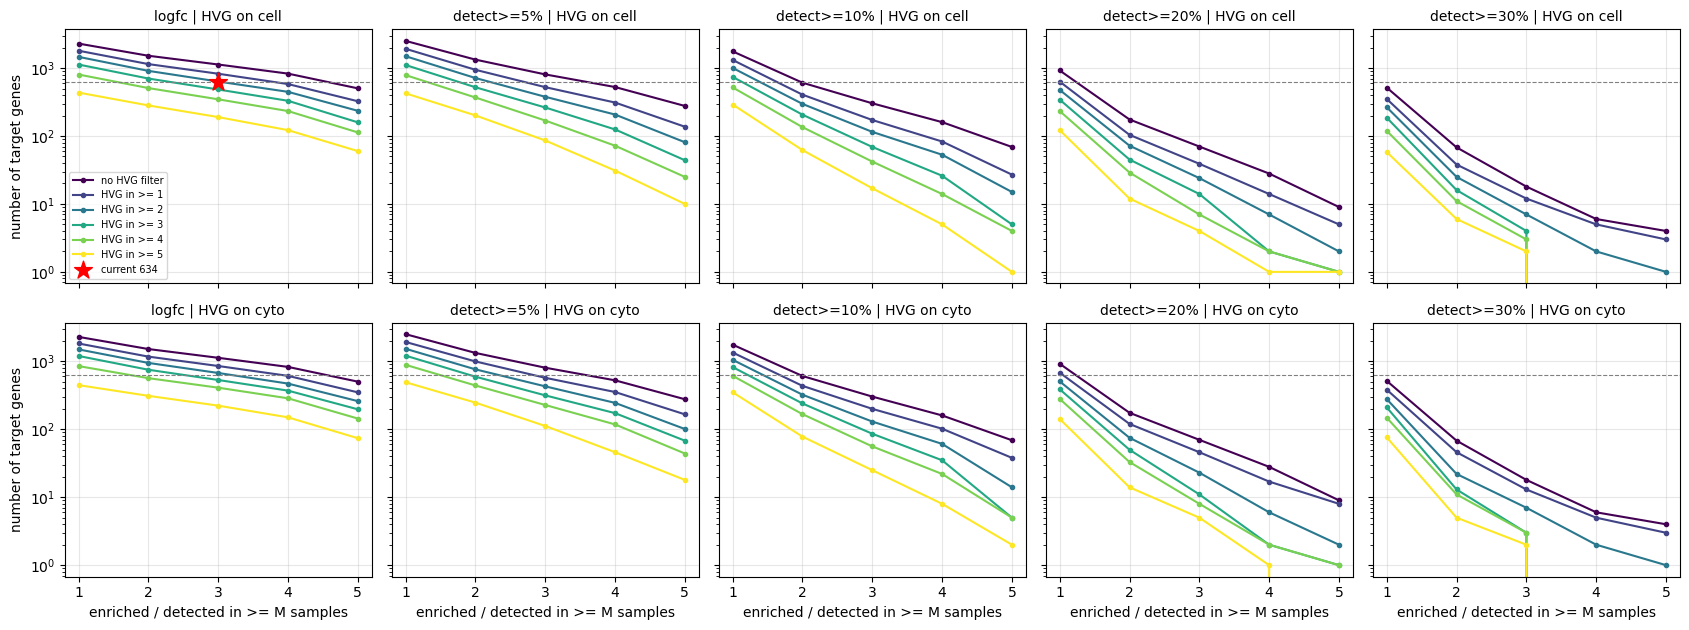

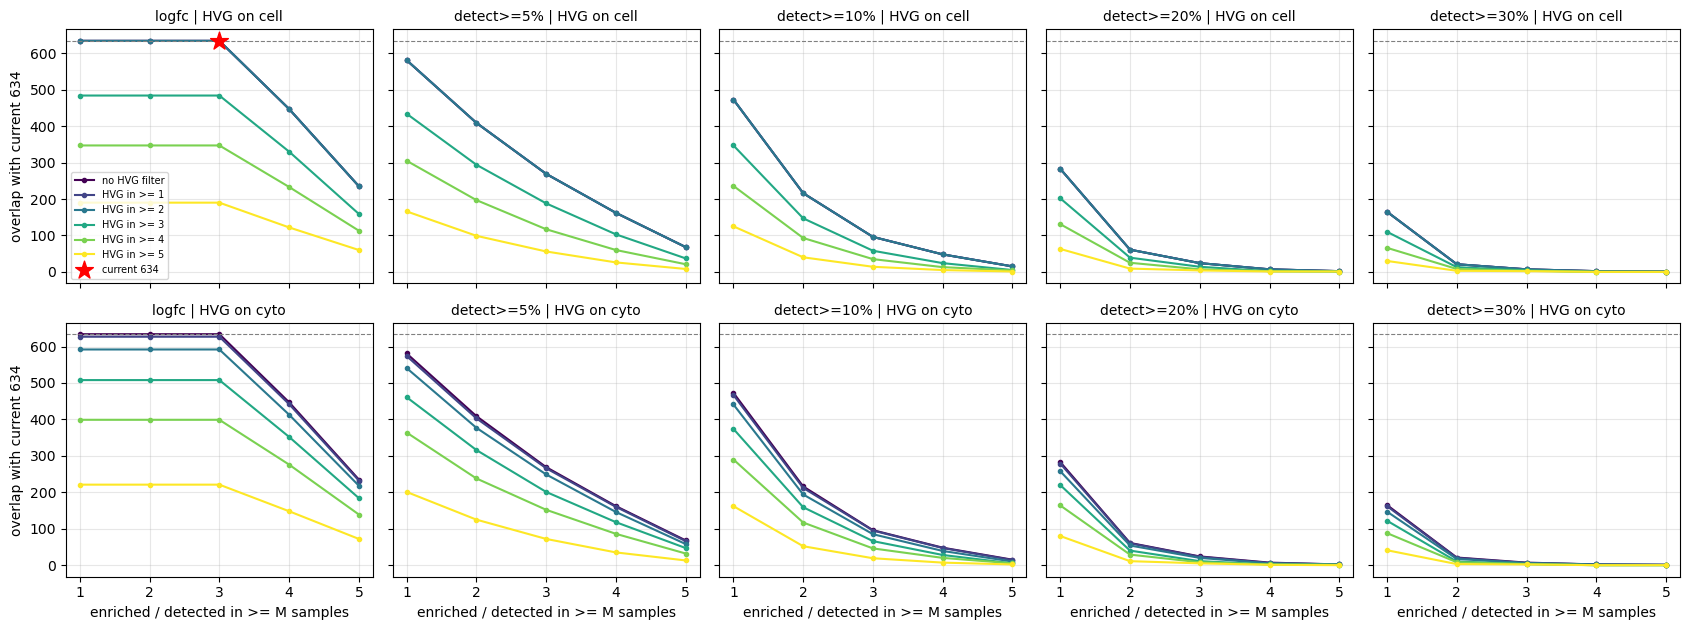

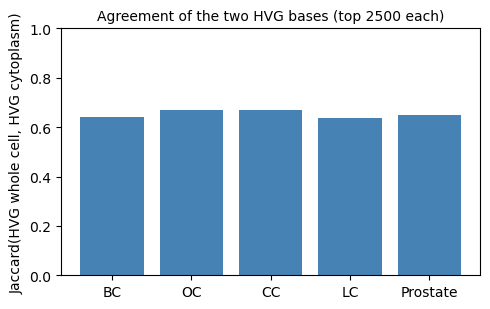

In [7]:
def trajectory_plot(value, ylabel, fname, logy, ref=None):
    enr_list, hvg_list = list(enr_cols), list(hvg_cols)
    fig, axes = plt.subplots(len(hvg_list), len(enr_list), figsize=(3.4 * len(enr_list), 3.2 * len(hvg_list)),
                             sharex=True, sharey=True)
    cmap = plt.get_cmap("viridis", len(n_hvg_range))
    for i, h in enumerate(hvg_list):
        for j, e in enumerate(enr_list):
            ax = axes[i, j]
            g = grid[(grid["enrichment"] == e) & (grid["hvg_basis"] == h)]
            for k, n in enumerate(n_hvg_range):
                gg = g[g["n_hvg_samples"] == n].sort_values("m_enriched_samples")
                ax.plot(gg["m_enriched_samples"], gg[value], marker="o", ms=3, color=cmap(k),
                        label=("no HVG filter" if n == 0 else f"HVG in >= {n}"))
            if ref is not None:
                ax.axhline(ref, color="grey", ls="--", lw=0.8)
            if e == "logfc" and h == "cell":
                cur = g[(g["n_hvg_samples"] == current_n) & (g["m_enriched_samples"] == current_m)]
                ax.scatter(cur["m_enriched_samples"], cur[value], marker="*", s=180, color="red", zorder=5,
                           label="current 634")
            if logy:
                ax.set_yscale("log")
            ax.set_title(f"{e} | HVG on {h}", fontsize=10)
            ax.set_xticks(m_range)
            if i == len(hvg_list) - 1:
                ax.set_xlabel("enriched / detected in >= M samples")
            if j == 0:
                ax.set_ylabel(ylabel)
            ax.grid(alpha=0.3)
    axes[0, 0].legend(fontsize=7, loc="lower left")
    fig.tight_layout()
    fig.savefig(out_dir + fname, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

trajectory_plot("n_genes", "number of target genes", "trajectory_counts.png", logy=True, ref=len(current_genes))
trajectory_plot("overlap_634", "overlap with current 634", "trajectory_overlap.png", logy=False, ref=len(current_genes))

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.bar(agree["sample"], agree["jaccard"], color="steelblue")
ax.set_ylabel("Jaccard(HVG whole cell, HVG cytoplasm)")
ax.set_ylim(0, 1)
ax.set_title("Agreement of the two HVG bases (top 2500 each)", fontsize=10)
fig.tight_layout()
fig.savefig(out_dir + "hvg_basis_agreement.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

## 5. Summary

In [8]:
lines = []
lines.append("Target gene set sensitivity (5_target_gene_sensitivity.ipynb)")
lines.append(f"Fixed: n_top_hvg = {n_top_hvg}; bottom-10% total-count drop per sample (gene universe = enrichment_results.csv).")
lines.append(f"Current rule (logFC/FDR, HVG on whole cell, HVG in >= {current_n}, enriched in >= {current_m}) reproduces the saved set: {len(reproduced)} genes.")
lines.append("")
lines.append(f"Scenarios at the current thresholds (N >= {current_n}, M >= {current_m}):")
for _, r in at_current.iterrows():
    lines.append(f"  {r['enrichment']:>12s} | HVG on {r['hvg_basis']:4s}: {int(r['n_genes']):5d} genes, overlap {int(r['overlap_634']):3d}, "
                 f"lost {int(r['lost_634']):3d}, new {int(r['new_genes']):5d}, Jaccard {r['jaccard_634']:.2f}")
lines.append("")
lines.append("Range of the gene count over N (0..5) and M (1..5):")
for (e, h), g in grid.groupby(["enrichment", "hvg_basis"], sort=False):
    g1 = g[g["n_hvg_samples"] >= 1]
    lines.append(f"  {e:>12s} | HVG on {h:4s}: no HVG filter {int(g[g['n_hvg_samples']==0]['n_genes'].max())} (M=1) .. "
                 f"{int(g[g['n_hvg_samples']==0]['n_genes'].min())} (M=5); with HVG filter {int(g1['n_genes'].max())} (N=1, M=1) .. {int(g1['n_genes'].min())} (N=5, M=5)")
lines.append("")
lines.append("HVG basis agreement (top 2500 whole cell vs top 2500 cytoplasm):")
for _, r in agree.iterrows():
    lines.append(f"  {r['sample']:>8s}: intersection {int(r['intersection'])}, Jaccard {r['jaccard']:.2f}")
lines.append(f"  current 634 genes that are HVG(cyto) in >= {current_n} samples: {cur_cyto_hvg}")
lines.append("")
lines.append(f"Detection criterion instead of logFC (HVG on whole cell, N >= {current_n}, M >= {current_m}):")
for _, r in det.iterrows():
    lines.append(f"  detect >= {int(round(r['threshold']*100)):2d}%: {int(r['n_genes_cellHVG_N2_M3'])} genes, overlap {int(r['overlap_634'])}, "
                 f"new {int(r['new_genes'])}, of which nucleus-enriched (log2FC < 0 in a majority of samples) {int(r['new_genes_nucleus_enriched_majority'])}; "
                 f"current 634 detected per sample: " + ", ".join(f"{s} {int(r[f'current634_detected_{s}'])}" for s in short.values()))
summary = "\n".join(lines)
with open(out_dir + "summary.txt", "w") as f:
    f.write(summary + "\n")
print(summary)

Target gene set sensitivity (5_target_gene_sensitivity.ipynb)
Fixed: n_top_hvg = 2500; bottom-10% total-count drop per sample (gene universe = enrichment_results.csv).
Current rule (logFC/FDR, HVG on whole cell, HVG in >= 2, enriched in >= 3) reproduces the saved set: 634 genes.

Scenarios at the current thresholds (N >= 2, M >= 3):
         logfc | HVG on cell:   634 genes, overlap 634, lost   0, new     0, Jaccard 1.00
         logfc | HVG on cyto:   675 genes, overlap 592, lost  42, new    83, Jaccard 0.83
    detect>=5% | HVG on cell:   378 genes, overlap 269, lost 365, new   109, Jaccard 0.36
    detect>=5% | HVG on cyto:   429 genes, overlap 249, lost 385, new   180, Jaccard 0.31
   detect>=10% | HVG on cell:   115 genes, overlap  96, lost 538, new    19, Jaccard 0.15
   detect>=10% | HVG on cyto:   130 genes, overlap  85, lost 549, new    45, Jaccard 0.13
   detect>=20% | HVG on cell:    24 genes, overlap  24, lost 610, new     0, Jaccard 0.04
   detect>=20% | HVG on cyto:    23